# Multiscale Glow on MNIST

This notebook carries the ring normalizing-flow sequence into MNIST with a compact but representative **unconditional image normalizing flow** built from the key architectural ideas used by Glow:

- uniform dequantization and a logit transform;
- multiscale squeezing and factor-out;
- ActNorm;
- learned invertible $1\times1$ channel mixing;
- convolutional affine coupling;
- a learned conditional split prior.

### Learning goals
1. Track exact densities through every invertible transformation.
2. Understand why image flows need multiscale channel mixing.
3. Distinguish exact reconstruction, exact likelihood, and perceptual sample quality.
4. Measure bits per dimension and sampling temperature effects.
5. Compare fast parallel sampling with architectural constraints imposed by invertibility.

> **Execution note:** Representative outputs are embedded below. **Run modes:** `RUN_MODE = "lecture"` (the default) loads the bundled checkpoint and avoids retraining. Use `"full"` to train the documented configuration, or `"smoke"` for a reduced CPU pipeline check. Smoke-mode checkpoints and results are deliberately separate and are **not** representative model results.

## Before you begin

**Prerequisites.** Review change of variables, Jacobian determinants, maximum likelihood, and invertible transformations. Familiarity with convolutional tensors helps. Notebook 02 (the ring flow) is the conceptual predecessor.

> **Notation and orientation**
> - $x$ is a discrete 8-bit image, $u$ is dequantization noise, $y$ is the logit-preprocessed image, and $z=f_\theta(y)$ is the multiscale latent.
> - **Unchanged from the ring:** bijectivity, exact log-determinant bookkeeping, likelihood training, and one-pass inversion.
> - **New at image scale:** dequantization, squeezing/factor-out, channel mixing, and bits per dimension (bpd).

## 1. Setup and configuration

The full configuration is designed to demonstrate the family rather than minimize runtime. The explicit smoke mode reduces data, depth, width, and epochs for a quick CPU check.

In [1]:
import gzip
import math
import random
import struct
import time
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"

RUN_MODE = "lecture"  # "lecture", "full", or "smoke"
if RUN_MODE not in {"lecture", "full", "smoke"}:
    raise ValueError("RUN_MODE must be 'lecture', 'full', or 'smoke'.")
TRAIN = RUN_MODE != "lecture"
EPOCHS = 1 if RUN_MODE == "smoke" else 60
BATCH_SIZE = 128
STEPS_PER_LEVEL = (2, 2) if RUN_MODE == "smoke" else (8, 12)
HIDDEN_CHANNELS = 32 if RUN_MODE == "smoke" else 128
LEARNING_RATE = 2e-4
NOTEBOOK_DIR = Path("notebooks") if Path("notebooks").is_dir() else Path(".")
checkpoint_name = "glow_mnist_smoke.pt" if RUN_MODE == "smoke" else "glow_mnist.pt"
CHECKPOINT = NOTEBOOK_DIR / "checkpoints" / checkpoint_name
CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)

PLOT_THEME = "light"  # Change to "dark" for the dark plot palette.
if PLOT_THEME not in {"light", "dark"}:
    raise ValueError("PLOT_THEME must be 'light' or 'dark'.")

# Start from Matplotlib defaults so light mode keeps the standard coloring.
plt.style.use("default")
if PLOT_THEME == "dark":
    plt.style.use("dark_background")
    plt.rcParams.update(
        {
            "figure.facecolor": "#0a0f18",
            "figure.edgecolor": "#0a0f18",
            "axes.facecolor": "#111926",
            "axes.edgecolor": "#e8eff9",
            "axes.labelcolor": "#e8eff9",
            "axes.titlecolor": "#e8eff9",
            "text.color": "#e8eff9",
            "xtick.color": "#e8eff9",
            "ytick.color": "#e8eff9",
            "grid.color": "#2b3340",
            "savefig.facecolor": "#0a0f18",
            "savefig.edgecolor": "#0a0f18",
        }
    )

PLOT_REFERENCE_COLOR = "black" if PLOT_THEME == "light" else "#6cd2e8"
PLOT_GENERATED_COLOR = "tab:orange" if PLOT_THEME == "light" else "#f09a4b"
PLOT_GUIDE_COLOR = "black" if PLOT_THEME == "light" else "#e8eff9"

plt.rcParams.update({"figure.figsize": (7, 5), "axes.grid": False, "font.size": 11})
print(f"PyTorch {torch.__version__} | device: {DEVICE} | run mode: {RUN_MODE}")
if RUN_MODE == "smoke":
    print("SMOKE MODE: reduced-cost pipeline check; results are not representative.")

PyTorch 2.12.0+cu130 | device: cuda | run mode: lecture


## 2. Load MNIST

Pixels remain integer-valued until preprocessing so the dequantization correction is explicit. Labels are retained only for diagnostics. The flow is unconditional.

In [2]:
DATA_DIR = NOTEBOOK_DIR / "data/mnist"
DATA_DIR.mkdir(parents=True, exist_ok=True)
BASE_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"
FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}
for filename in FILES.values():
    destination = DATA_DIR / filename
    if not destination.exists():
        urlretrieve(BASE_URL + filename, destination)


def read_images(path):
    with gzip.open(path, "rb") as file:
        magic, count, height, width = struct.unpack(">IIII", file.read(16))
        assert magic == 2051
        data = np.frombuffer(file.read(), dtype=np.uint8).copy()
    return torch.from_numpy(data.reshape(count, 1, height, width))


def read_labels(path):
    with gzip.open(path, "rb") as file:
        magic, count = struct.unpack(">II", file.read(8))
        assert magic == 2049
        data = np.frombuffer(file.read(), dtype=np.uint8).copy()
    return torch.from_numpy(data.astype(np.int64))


x_train = read_images(DATA_DIR / FILES["train_images"])
y_train = read_labels(DATA_DIR / FILES["train_labels"])
x_test = read_images(DATA_DIR / FILES["test_images"])
y_test = read_labels(DATA_DIR / FILES["test_labels"])
train_count = len(x_train) if RUN_MODE != "smoke" else min(2_048, len(x_train))
train_dataset = TensorDataset(x_train[:train_count], y_train[:train_count])
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    pin_memory=PIN_MEMORY,
    generator=torch.Generator().manual_seed(SEED),
)
test_loader = DataLoader(
    TensorDataset(x_test, y_test), batch_size=256, shuffle=False, pin_memory=PIN_MEMORY
)
print(f"Training: {tuple(x_train.shape)} | test: {tuple(x_test.shape)}")

Training: (60000, 1, 28, 28) | test: (10000, 1, 28, 28)


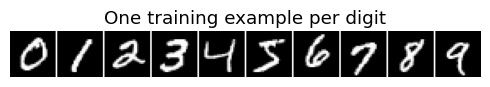

In [3]:
def show_image_grid(images, nrow=10, title=None, value_range=(0, 1)):
    images = images.detach().cpu()
    if images.ndim == 4:
        images = images[:, 0]
    ncol = int(np.ceil(len(images) / nrow))
    canvas = torch.ones(ncol * 28 + ncol - 1, nrow * 28 + nrow - 1)
    for index, image in enumerate(images):
        row, column = divmod(index, nrow)
        top, left = row * 29, column * 29
        canvas[top : top + 28, left : left + 28] = image
    fig, ax = plt.subplots(figsize=(nrow, ncol))
    ax.imshow(canvas, cmap="gray", vmin=value_range[0], vmax=value_range[1])
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


indices = [int(torch.where(y_train == digit)[0][0]) for digit in range(10)]
show_image_grid(x_train[indices].float() / 255, 10, "One training example per digit")

## 3. Dequantization and logit preprocessing

A continuous flow cannot directly model isolated 8-bit values. Uniform dequantization creates continuous observations:

$$u\sim U[0,1),\qquad x=\frac{x_{integer}+u}{256}.$$

Constrain values away from the endpoints and apply a logit:

$$x'=\alpha+(1-2\alpha)x,\qquad y=\log x'-\log(1-x').$$

The preprocessing Jacobian is included in the exact continuous density. Subtracting $784\log256$ gives a lower bound on discrete image likelihood.

In [4]:
ALPHA = 1e-5
N_PIXELS = 28 * 28
LOG_2PI = math.log(2 * math.pi)


def preprocess(integer_images, dequantize=True):
    noise = torch.rand_like(integer_images, dtype=torch.float32) if dequantize else 0.5
    x = (integer_images.float() + noise) / 256
    constrained = ALPHA + (1 - 2 * ALPHA) * x
    y = torch.log(constrained) - torch.log1p(-constrained)
    log_det = (
        math.log(1 - 2 * ALPHA) - torch.log(constrained) - torch.log1p(-constrained)
    )
    return y, log_det.flatten(1).sum(1)


def inverse_preprocess(y):
    constrained = torch.sigmoid(y)
    return ((constrained - ALPHA) / (1 - 2 * ALPHA)).clamp(0, 1)


def gaussian_log_prob(value, mean, log_std):
    return (
        (
            -0.5 * ((value - mean) * torch.exp(-log_std)).square()
            - log_std
            - 0.5 * LOG_2PI
        )
        .flatten(1)
        .sum(1)
    )


def bits_per_dimension(continuous_log_prob):
    return -(continuous_log_prob - N_PIXELS * math.log(256)) / (N_PIXELS * math.log(2))

## 4. Invertible building blocks

A Glow step contains:

1. **ActNorm:** learned channel-wise location and scale, initialized from data;
2. **invertible $1\times1$ convolution:** learned channel mixing with tractable determinant;
3. **affine coupling:** half the channels predict scale and shift for the other half.

The coupling conditioner may be arbitrarily expressive because it need not be inverted. Its final layer starts at zero, making each coupling transformation initially the identity.

In [5]:
def squeeze2d(x):
    b, c, h, w = x.shape
    return (
        x.reshape(b, c, h // 2, 2, w // 2, 2)
        .permute(0, 1, 3, 5, 2, 4)
        .reshape(b, 4 * c, h // 2, w // 2)
    )


def unsqueeze2d(x):
    b, c, h, w = x.shape
    return (
        x.reshape(b, c // 4, 2, 2, h, w)
        .permute(0, 1, 4, 2, 5, 3)
        .reshape(b, c // 4, 2 * h, 2 * w)
    )


class ActNorm(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.bias = nn.Parameter(torch.zeros(1, channels, 1, 1))
        self.log_scale = nn.Parameter(torch.zeros(1, channels, 1, 1))
        self.register_buffer("initialized", torch.tensor(False))

    @torch.no_grad()
    def initialize(self, x):
        mean = x.mean((0, 2, 3), keepdim=True)
        std = x.std((0, 2, 3), keepdim=True).clamp_min(1e-6)
        self.bias.copy_(-mean)
        self.log_scale.copy_(-std.log())
        self.initialized.fill_(True)

    def forward(self, x):
        if not bool(self.initialized):
            self.initialize(x)
        y = (x + self.bias) * torch.exp(self.log_scale)
        ld = x.shape[2] * x.shape[3] * self.log_scale.sum()
        return y, ld.expand(len(x))

    def inverse(self, y):
        return y * torch.exp(-self.log_scale) - self.bias


class Invertible1x1Conv(nn.Module):
    def __init__(self, channels):
        super().__init__()
        q, _ = torch.linalg.qr(torch.randn(channels, channels))
        self.weight = nn.Parameter(q)

    def forward(self, x):
        _, logabsdet = torch.linalg.slogdet(self.weight.float())
        y = F.conv2d(x, self.weight[:, :, None, None].to(x.dtype))
        return y, (x.shape[2] * x.shape[3] * logabsdet).to(x.dtype).expand(len(x))

    def inverse(self, y):
        inverse = torch.linalg.inv(self.weight.float()).to(y.dtype)
        return F.conv2d(y, inverse[:, :, None, None])


class CouplingNet(nn.Module):
    def __init__(self, in_channels, out_channels, hidden):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 3, padding=1),
            nn.SiLU(),
            nn.Conv2d(hidden, hidden, 1),
            nn.SiLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1),
            nn.SiLU(),
            nn.Conv2d(hidden, out_channels, 3, padding=1),
        )
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, x):
        return self.net(x)


class AffineCoupling(nn.Module):
    def __init__(self, channels, hidden):
        super().__init__()
        self.split = channels // 2
        self.conditioner = CouplingNet(self.split, 2 * (channels - self.split), hidden)

    def parameters_from(self, first):
        shift, raw_scale = self.conditioner(first).chunk(2, 1)
        return shift, 1.8 * torch.tanh(raw_scale / 1.8)

    def forward(self, x):
        first, second = x[:, : self.split], x[:, self.split :]
        shift, log_scale = self.parameters_from(first)
        transformed = second * torch.exp(log_scale) + shift
        return torch.cat([first, transformed], 1), log_scale.flatten(1).sum(1)

    def inverse(self, y):
        first, transformed = y[:, : self.split], y[:, self.split :]
        shift, log_scale = self.parameters_from(first)
        return torch.cat([first, (transformed - shift) * torch.exp(-log_scale)], 1)


class GlowStep(nn.Module):
    def __init__(self, channels, hidden):
        super().__init__()
        self.actnorm = ActNorm(channels)
        self.mix = Invertible1x1Conv(channels)
        self.coupling = AffineCoupling(channels, hidden)

    def forward(self, x):
        x, ld1 = self.actnorm(x)
        x, ld2 = self.mix(x)
        x, ld3 = self.coupling(x)
        return x, ld1 + ld2 + ld3

    def inverse(self, z):
        return self.actnorm.inverse(self.mix.inverse(self.coupling.inverse(z)))

## 5. Multiscale Glow

After the first level, half the channels are factored out as $z_1$. The remaining channels continue through another squeeze and deeper flow level. A learned split prior models

$$p(z_1\mid h)=\mathcal N(\mu_\theta(h),\operatorname{diag}(\sigma^2_\theta(h))).$$

The final tensor $z_2$ uses a standard-normal prior. Factoring out fine-scale variables reduces compute while later levels model global structure.

In [6]:
class GlowMNIST(nn.Module):
    def __init__(self, steps_per_level=(8, 12), hidden=128):
        super().__init__()
        self.level1 = nn.ModuleList(
            [GlowStep(4, hidden) for _ in range(steps_per_level[0])]
        )
        self.split_prior = CouplingNet(
            2, 4, hidden
        )  # mean and log-std for two factored channels
        self.level2 = nn.ModuleList(
            [GlowStep(8, hidden) for _ in range(steps_per_level[1])]
        )

    def encode(self, y):
        h = squeeze2d(y)
        total = torch.zeros(len(y), device=y.device, dtype=y.dtype)
        for step in self.level1:
            h, ld = step(h)
            total += ld
        z1, h = h.chunk(2, 1)
        prior_mean, prior_raw = self.split_prior(h).chunk(2, 1)
        prior_log_std = 2 * torch.tanh(prior_raw / 2)
        h = squeeze2d(h)
        for step in self.level2:
            h, ld = step(h)
            total += ld
        z2 = h
        log_prior = gaussian_log_prob(
            z1, prior_mean, prior_log_std
        ) + gaussian_log_prob(z2, torch.zeros_like(z2), torch.zeros_like(z2))
        return (z1, z2), total + log_prior

    def decode(self, latents):
        z1, z2 = latents
        h = z2
        for step in reversed(self.level2):
            h = step.inverse(h)
        h = unsqueeze2d(h)
        h = torch.cat([z1, h], 1)
        for step in reversed(self.level1):
            h = step.inverse(h)
        return unsqueeze2d(h)

    def log_prob(self, integer_images, dequantize=True):
        y, pre_ld = preprocess(integer_images, dequantize)
        _, flow_and_prior = self.encode(y)
        return flow_and_prior + pre_ld

    @torch.no_grad()
    def sample(self, n, temperature=1.0):
        z2 = temperature * torch.randn(
            n, 8, 7, 7, device=next(self.parameters()).device
        )
        h = z2
        for step in reversed(self.level2):
            h = step.inverse(h)
        h = unsqueeze2d(h)
        mean, raw = self.split_prior(h).chunk(2, 1)
        log_std = 2 * torch.tanh(raw / 2)
        z1 = mean + temperature * torch.exp(log_std) * torch.randn_like(mean)
        h = torch.cat([z1, h], 1)
        for step in reversed(self.level1):
            h = step.inverse(h)
        return inverse_preprocess(unsqueeze2d(h))


model = GlowMNIST(STEPS_PER_LEVEL, HIDDEN_CHANNELS).to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 3,678,084


## 6. Invertibility test

Run this before training. It verifies the complete deterministic transform for fixed latent tensors. Dequantization itself is stochastic and therefore tested separately through deterministic midpoint preprocessing.

### Predict before running

> **Commit to a prediction:** what reconstruction error should a correctly implemented flow produce after preprocessing, forward transformation, and exact inversion? Justify which operations could introduce only floating-point error.

In [7]:
probe, _ = preprocess(x_train[:4].to(DEVICE), dequantize=False)
latents, _ = model.encode(probe)
with torch.no_grad():
    recovered = model.decode(latents)
error = (probe - recovered).abs().max().item()
print(f"Maximum multiscale round-trip error: {error:.2e}")
assert error < 1e-4
assert latents[0].shape == (4, 2, 14, 14) and latents[1].shape == (4, 8, 7, 7)

Maximum multiscale round-trip error: 9.06e-06


> **Expected observation / interpretation.** The maximum error should be near floating-point precision. Exact reconstruction checks bijectivity. It does not by itself imply good likelihood or perceptually strong samples.

## 7. Train by exact maximum likelihood

The optimizer minimizes negative log likelihood. The displayed bits/dim includes dequantization and every Jacobian term. Checkpoints store model, optimizer, configuration, and training history.

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS)
history = []
start_epoch = 0
training_started = time.time()

if not TRAIN:
    checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model"])
    history = checkpoint["history"]
    start_epoch = checkpoint["epoch"]
    print(f"Loaded {CHECKPOINT} from epoch {start_epoch}")
else:
    for epoch in range(start_epoch + 1, EPOCHS + 1):
        model.train()
        total_bpd = 0
        for images, _ in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            log_prob = model.log_prob(images, dequantize=True)
            loss = -log_prob.mean() / N_PIXELS
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5)
            optimizer.step()
            total_bpd += bits_per_dimension(log_prob.detach()).sum().item()
        scheduler.step()
        average = total_bpd / (len(train_loader) * train_loader.batch_size)
        history.append(average)
        print(f"epoch {epoch:3d}/{EPOCHS} | {average:.3f} bits/dim")
        torch.save(
            {
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "history": history,
                "epoch": epoch,
            },
            CHECKPOINT,
        )
print(f"Elapsed: {time.time()-training_started:.1f} s" if TRAIN else "Checkpoint ready")

Loaded checkpoints/glow_mnist.pt from epoch 60
Checkpoint ready


## 8. Likelihood, exact reconstruction, and sampling

These three diagnostics test different properties:

- likelihood measures density fit;
- reconstruction must be exact by architecture;
- prior samples test whether typical latent values decode to convincing images.

Temperature below 1 often improves apparent sharpness at the cost of diversity and no longer samples the trained model exactly.

### Predict before running

> **Commit to a prediction:** before viewing likelihood and samples, predict how lower sampling temperature will change sharpness and diversity, and explain why dequantization is still required for meaningful bpd on discrete pixels.

Test dequantization bound: 1.145 bits/dim


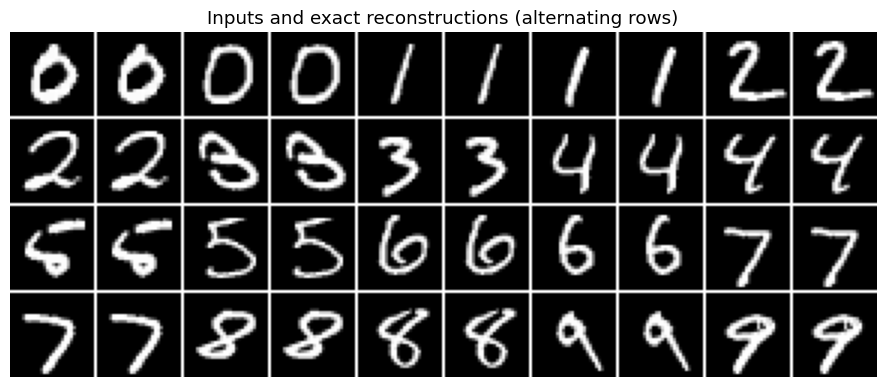

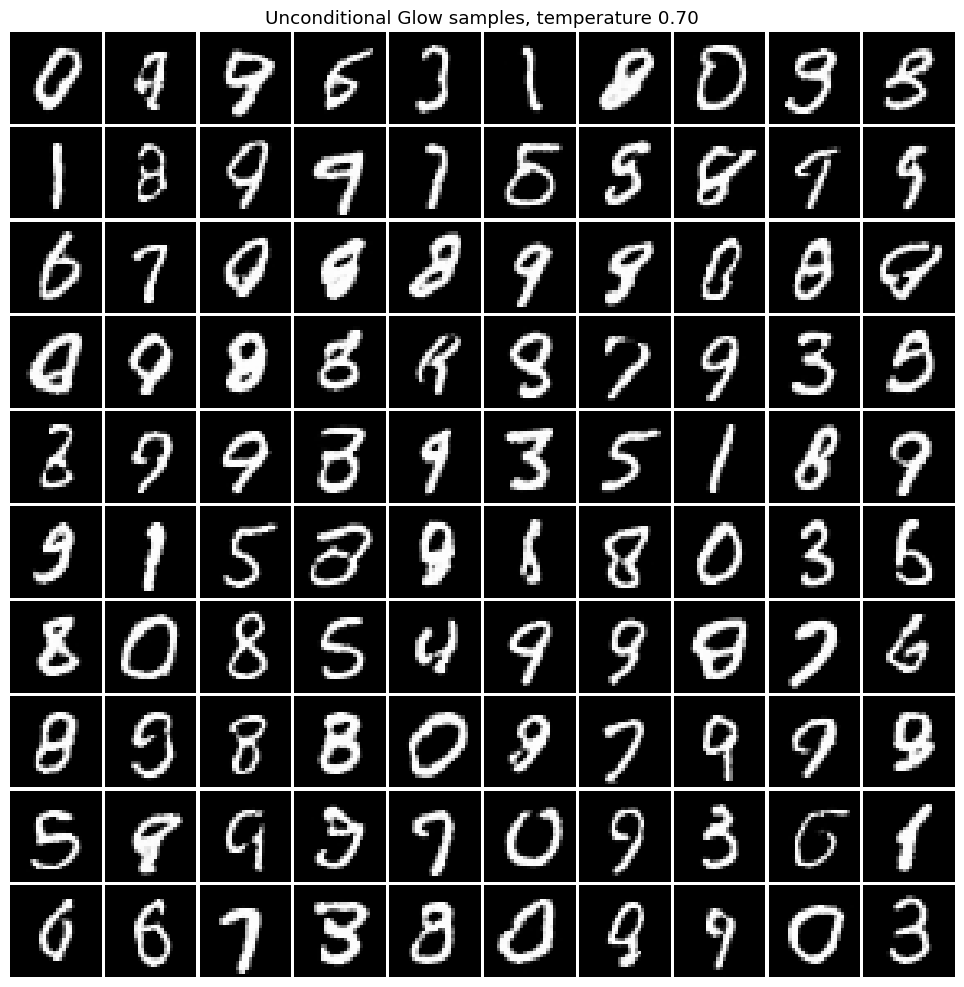

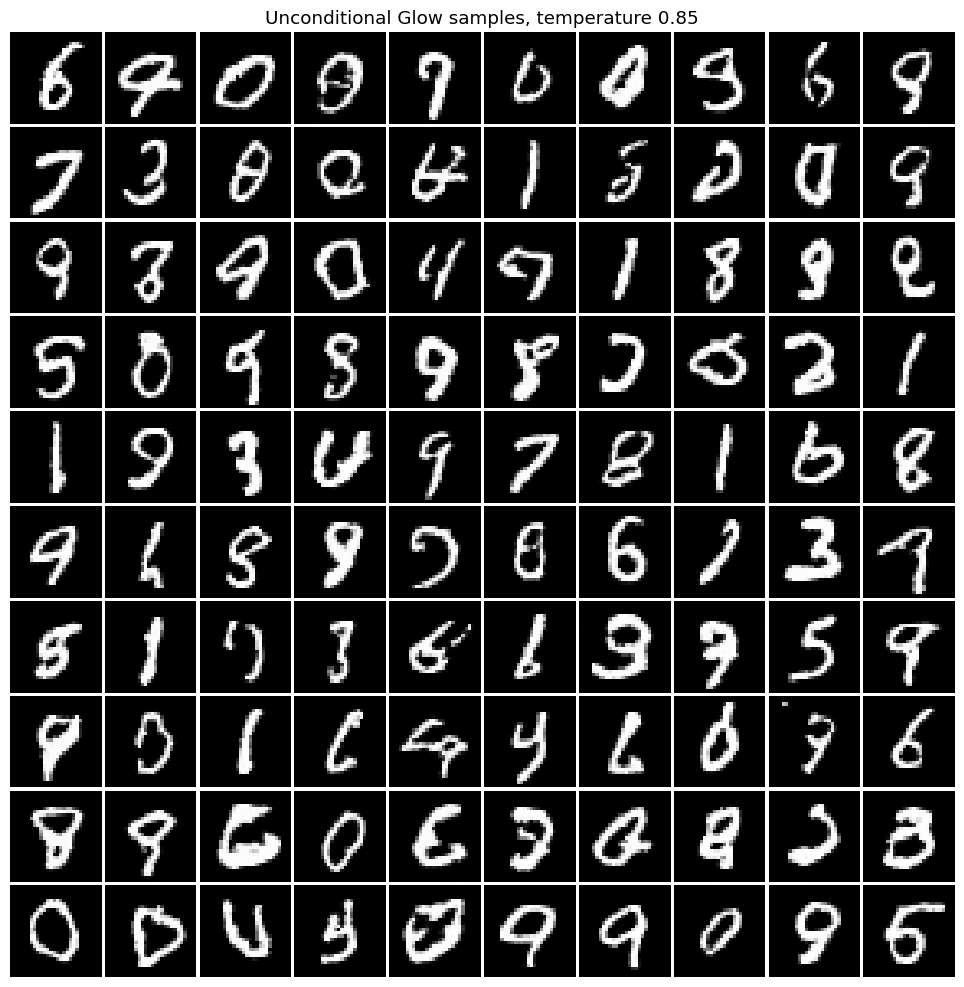

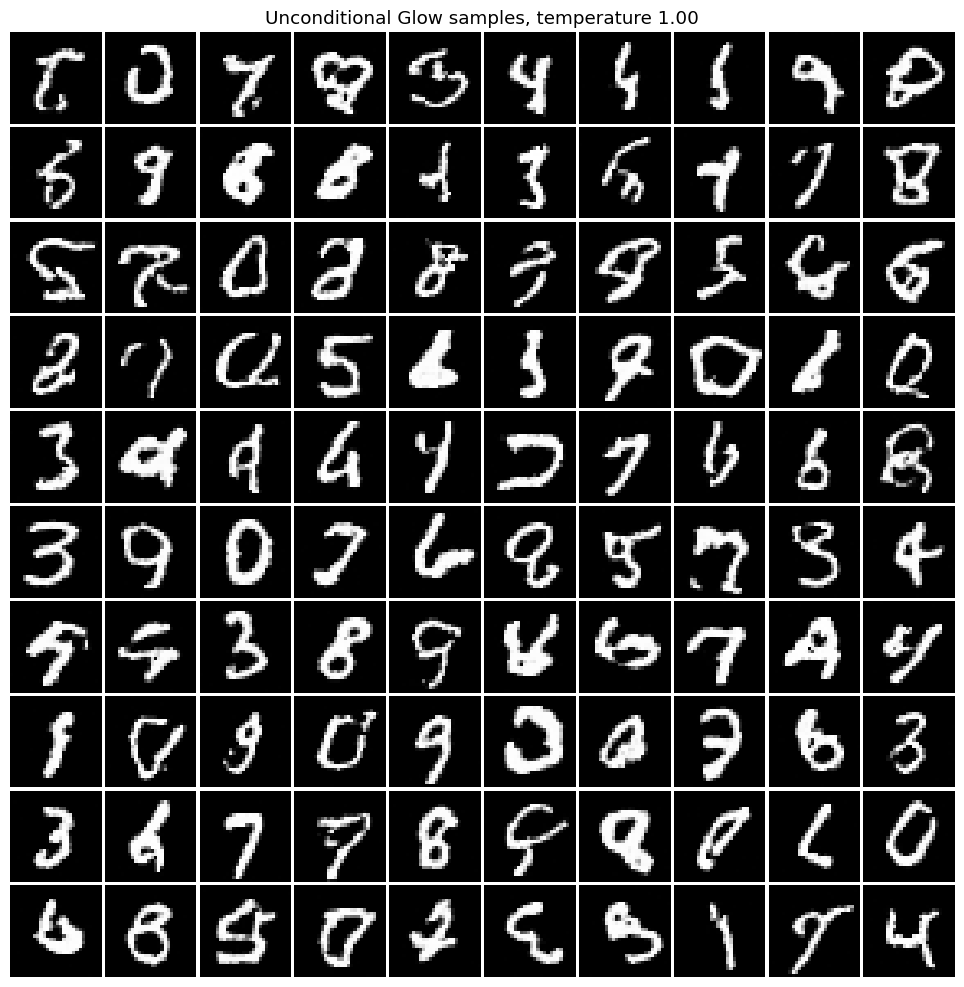

In [9]:
model.eval()
# Test likelihood (use multiple dequantizations for a less noisy estimate if desired).
total = 0
with torch.no_grad():
    for images, _ in test_loader:
        total += (
            bits_per_dimension(model.log_prob(images.to(DEVICE), dequantize=True))
            .sum()
            .item()
        )
print(f"Test dequantization bound: {total/len(x_test):.3f} bits/dim")

indices = torch.cat([torch.where(y_test == d)[0][:2] for d in range(10)])
y, _ = preprocess(x_test[indices].to(DEVICE), dequantize=False)
with torch.no_grad():
    latents, _ = model.encode(y)
    recon = inverse_preprocess(model.decode(latents)).cpu()
paired = torch.stack([(x_test[indices].float() / 255), recon], 1).reshape(-1, 1, 28, 28)
show_image_grid(paired, 10, "Inputs and exact reconstructions (alternating rows)")

for temperature in [0.7, 0.85, 1.0]:
    with torch.no_grad():
        samples = model.sample(100, temperature).cpu()
    show_image_grid(
        samples, 10, f"Unconditional Glow samples, temperature {temperature:.2f}"
    )

> **Expected observation / interpretation.** Lower temperature concentrates latent draws, often making samples more regular but less diverse. Dequantization converts discrete masses into a continuous density problem. The bpd metric includes the corresponding preprocessing/Jacobian accounting. Exact inversion can coexist with imperfect sample quality.

## 9. Latent interpolation and speed

Spherical interpolation probes continuity. Sampling-time measurement demonstrates a core flow advantage: all images are produced in one inverse network pass rather than through pixels or diffusion steps.

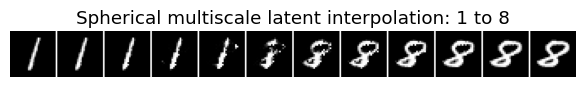

100 samples: 0.017 s


In [10]:
def slerp(a, b, weights):
    flat_a = torch.cat([part.flatten() for part in a])
    flat_b = torch.cat([part.flatten() for part in b])
    ua, ub = F.normalize(flat_a, dim=0), F.normalize(flat_b, dim=0)
    angle = torch.acos(torch.clamp(torch.dot(ua, ub), -1 + 1e-6, 1 - 1e-6))
    den = torch.sin(angle)
    vectors = torch.stack(
        [
            torch.sin((1 - w) * angle) / den * flat_a
            + torch.sin(w * angle) / den * flat_b
            for w in weights
        ]
    )
    sizes = [part.numel() for part in a]
    splits = torch.split(vectors, sizes, dim=1)
    return [
        part.reshape(len(weights), *template.shape) for part, template in zip(splits, a)
    ]


endpoints = x_test[
    [int(torch.where(y_test == 1)[0][0]), int(torch.where(y_test == 8)[0][0])]
].to(DEVICE)
y, _ = preprocess(endpoints, dequantize=False)
with torch.no_grad():
    encoded, _ = model.encode(y)
    path = slerp(
        [z[0] for z in encoded],
        [z[1] for z in encoded],
        torch.linspace(0, 1, 12, device=DEVICE),
    )
    interpolation = inverse_preprocess(model.decode(path)).cpu()
show_image_grid(interpolation, 12, "Spherical multiscale latent interpolation: 1 to 8")

if DEVICE.type == "cuda":
    torch.cuda.synchronize()
start = time.perf_counter()
with torch.no_grad():
    _ = model.sample(100, 1.0)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
print(f"100 samples: {time.perf_counter()-start:.3f} s")

## 10. What this demonstrates

### Strengths
- exact normalized continuous density and exact dequantization bound;
- exact invertibility and reconstruction;
- fast, parallel one-pass sampling;
- stable maximum-likelihood training;
- meaningful latent interpolation.

### Costs and limitations
- invertibility constrains every transformation and preserves dimensionality before factor-out;
- image-specific flow engineering is substantially more involved than a VAE decoder;
- likelihood can favor low-level statistics that do not align perfectly with perception;
- good samples require multiscale mixing, expressive coupling networks, and adequate training;
- matrix inverses and determinants add numerical and computational considerations.

## Homework experiments

### Mini-experiment 1 — Remove invertible channel mixing
- **Hypothesis:** Without invertible $1\times1$ convolutions, fixed channel partitions reduce cross-channel interaction and worsen likelihood/sample quality.
- **Metric/plot:** Compare validation bpd, temperature-matched sample grids, and invertibility error.
- **Controls:** Keep levels, coupling networks, preprocessing, seed, epochs, and evaluation batch fixed.
- **Interpretation:** Attribute changes to channel mixing only if numerical invertibility remains intact. 

### Mini-experiment 2 — Sampling temperature
- **Hypothesis:** Lower temperature improves regularity at the cost of coverage. A higher temperature increases diversity and artifacts.
- **Metric/plot:** Plot evaluator class entropy or effective classes and sample-quality statistics versus temperature, with fixed latent base draws.
- **Controls:** Reuse one checkpoint and scale the same latent draws. Keep sample count and evaluator fixed.
- **Interpretation:** Distinguish a sampling trade-off from model likelihood—temperature changes samples, not the fitted density.

### Extensions
- Replace the conditional split prior with a standard normal.
- Compare one and two multiscale levels.
- Replace affine coupling with rational-quadratic splines.
- Compare sample speed and likelihood with the autoregressive notebook.

## Exit ticket

1. Why are dequantization and its density correction needed for MNIST flow likelihoods?
<details><summary>Self-check</summary>A continuous density cannot assign meaningful mass directly to discrete pixels. Dequantization defines a continuous objective whose preprocessing terms enter bpd.</details>

2. What does near-zero reconstruction error prove (and not prove) about a normalizing flow?
<details><summary>Self-check</summary>It verifies numerical invertibility, not high likelihood or perceptual sample quality.</details>

3. How does lowering latent temperature usually change samples?
<details><summary>Self-check</summary>It concentrates draws, often increasing regularity while reducing diversity/coverage. The trained density itself is unchanged.</details>

## References and further reading

- [Dinh, Sohl-Dickstein & Bengio, “Density Estimation using Real NVP” (ICLR 2017)](https://openreview.net/forum?id=HkpbnH9lx): Establishes affine coupling and exact change-of-variables training.
- [Kingma & Dhariwal, “Glow” (NeurIPS 2018)](https://proceedings.neurips.cc/paper/2018/hash/d139db6a236200b21cc7f752979132d0-Abstract.html): Directly motivates ActNorm, invertible $1\times1$ convolutions, and the multiscale image architecture.